In [8]:
import os
import pandas as pd
import numpy as np

#Checks which datasets are in the folder
cleaned_files = os.listdir("data/cleaned")
print("Files in data/cleaned:", cleaned_files)

#This previewes the columns of each dataset in the folder
for file in cleaned_files:
    if file.endswith(".csv"):
        tempt_ddf = pd.read_csv(f"data/cleaned/{file}", nrows=2)
        print(f"\n{file} columns:", list(tempt_ddf.columns))

#This loads and standardizes the Texas Real Personal Income dataset
df = pd.read_csv("data/cleaned/TXRPI_cleaned.csv")
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date")
df["income_growth"] = df["Texas_Real_Personal_Income"].pct_change() * 100

#Defines the list and creates a future target column that is one period ahead
predictors = ["income_growth"]
df["actual_future"] = df["income_growth"].shift(-1)
#Keeps only predictors and target
model_df = df[predictors + ["actual_future"]].copy()

for col in model_df.columns:
   model_df[col] = pd.to_numeric(model_df[col], errors ="coerce")

model_df = model_df.dropna().reset_index(drop=True)
print(model_df.head()) 

#This just splits the data 80% training, and then 20% testing
split_index = int(len(model_df) * 0.8)
train_df = model_df.iloc[:split_index]
test_df = model_df.iloc[split_index:]
X_train = train_df[predictors].values
y_train = train_df["actual_future"].values
X_test = test_df[predictors].values
y_test = test_df["actual_future"].values

#This trains the linear regression model and adds a coloumn of 1s to X-train so it cna calculate the intercept
X_train_b = np.c_[np.ones((len(X_train), 1)), X_train]
theta, _, _, _ = np.linalg.lstsq(X_train_b, y_train, rcond=None)
intercept = theta[0]
coefficients = theta[1:]

#Generates the predictions
X_test_b = np.c_[np.ones((len(X_test), 1)), X_test]
predictions = X_test_b.dot(theta)

#the model will be using MAE, RMSE, and r^2 
errors = y_test - predictions
mae = np.abs(errors).mean()
rmse = np.sqrt((errors ** 2).mean())
ss_res = (errors ** 2).sum()
ss_tot = ((y_test - y_test.mean()) ** 2).sum()
r2 = 1- (ss_res / ss_tot)

print("--- Model Evaluation (Test Set) ---")
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"coefficient of Determination (R^2): {r2:.2f}\n")

#This prints the Intercept and the Coefficient
print("--- Model Parameters ---")
print(f"Intercept: {intercept:.4f}")
for name, coef in zip(predictors, coefficients):
    print(f"Coefficcinet for {name}: {coef:.4f}")







Files in data/cleaned: ['TXRPI_cleaned.csv']

TXRPI_cleaned.csv columns: ['Date', 'Texas_Real_Personal_Income']
   income_growth  actual_future
0      -3.994311       3.471239
1       3.471239       7.499089
2       7.499089       3.598257
3       3.598257       0.922765
4       0.922765       5.344590
--- Model Evaluation (Test Set) ---
Mean Absolute Error (MAE): 0.96
Root Mean Squared Error (RMSE): 1.05
coefficient of Determination (R^2): -0.06

--- Model Parameters ---
Intercept: 4.0109
Coefficcinet for income_growth: -0.0884


--- Model Comparison Table ---
               Model      MAE     RMSE         R2
Persistence Baseline 3.170478 3.583091 -11.424454
   Linear Regression 0.956409 1.047788  -0.062449


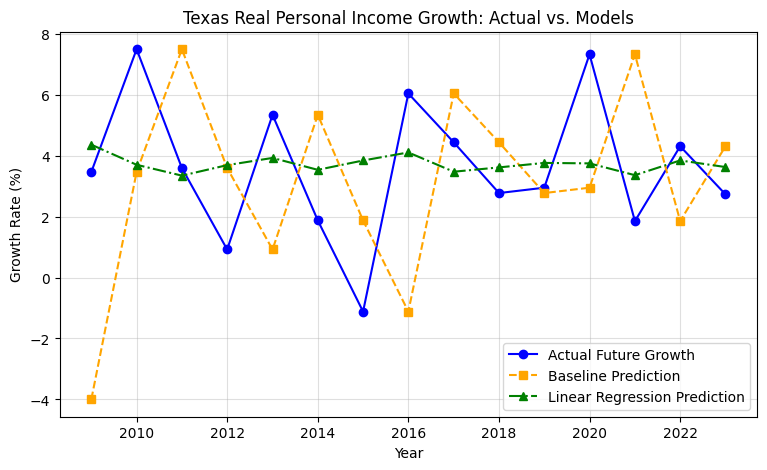

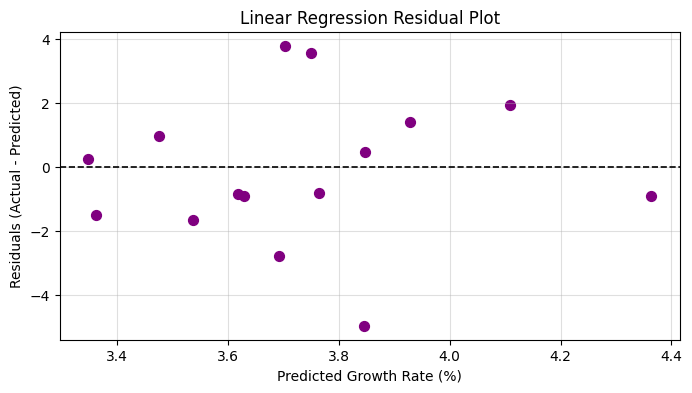

In [9]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#Creates the folder structure needed for the Github and creates the 4 subfolders if tehy don't exist
base_dir = "real_personal_income_growth"
for subfolder in ["data", "model", "results", "figures"]:
    os.makedirs(f"{base_dir}/{subfolder}", exist_ok=True)

#This loads and converts the dataset. Additionally it calculates the year-over-year percentage growth rate
csv_path = "data/cleaned/TXRPI_cleaned.csv" if os.path.exists("data/cleaned/TXRPI_cleaned.csv") else "cleaned/TXRPI_cleaned.csv"
df = pd.read_csv(csv_path)
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date")
df["income_growth"] = df["Texas_Real_Personal_Income"].pct_change() * 100

#Defines the predictor variables and creates the target variable and persistence baseline prediction
predictors = ["income_growth"]
df["actual_future"] = df["income_growth"].shift(-1)
df["baseline_prediction"] = df["income_growth"]

# Clean and drop missing values
#This makes sure to clean, drop and save the values from the data
model_df = df[["Date"] + predictors + ["actual_future", "baseline_prediction"]].dropna().reset_index(drop=True)
model_df[["Date"] + predictors + ["actual_future"]].to_csv(f"{base_dir}/data/modeling_data.csv", index=False)

#This splits the data into a 80/20 training/testing split
split_index = int(len(model_df) * 0.8)
train_df = model_df.iloc[:split_index].copy()
test_df = model_df.iloc[split_index:].copy()

#Extracts the values and predictions from the 20% testing split and calculates the prediction errors
y_test = test_df["actual_future"].values
base_pred = test_df["baseline_prediction"].values
base_errors = y_test - base_pred

#This is to calculate MAE, and RMSE
base_mae = np.abs(base_errors).mean()
base_rmse = np.sqrt((base_errors ** 2).mean())
base_r2 = 1 - ((base_errors ** 2).sum() / ((y_test - y_test.mean()) ** 2).sum())

# Saves baseline_predictions into results/baseline_predictions.csv
test_df[["Date", "actual_future", "baseline_prediction"]].to_csv(f"{base_dir}/results/baseline_predictions.csv", index=False)

# This will be the linear regression model, extrating the training predictors, training target, and testing predictors
X_train = train_df[predictors].values
y_train = train_df["actual_future"].values
X_test = test_df[predictors].values

#Adds a coloumn of 1s to X-train so OLS is able to calculate the y-intercept
#Additionally this uses numpy's least0squares solver to fit the model
X_train_b = np.c_[np.ones((len(X_train), 1)), X_train]
theta, _, _, _ = np.linalg.lstsq(X_train_b, y_train, rcond=None)
intercept = theta[0]
coefficients = theta[1:]

#To generate test predictions it adds a column of 1s to X-test and multiplys the theta
X_test_b = np.c_[np.ones((len(X_test), 1)), X_test]
reg_pred = X_test_b.dot(theta)
reg_errors = y_test - reg_pred  # Residuals

#Calculates the errors/residuals and evaluation metrics on the test set
reg_mae = np.abs(reg_errors).mean()
reg_rmse = np.sqrt((reg_errors ** 2).mean())
reg_r2 = 1 - ((reg_errors ** 2).sum() / ((y_test - y_test.mean()) ** 2).sum())

# Saves regression_predictions
test_df["regression_prediction"] = reg_pred
test_df[["Date", "actual_future", "regression_prediction"]].to_csv(f"{base_dir}/results/regression_predictions.csv", index=False)

# Saves coefficients
coef_df = pd.DataFrame({
    "Term": ["Intercept"] + predictors,
    "Coefficient": [intercept] + list(coefficients)
})
coef_df.to_csv(f"{base_dir}/results/coefficients.csv", index=False)

# This is the Model Comparison Table that will compare the errors of both models side by side
comparison_df = pd.DataFrame({
    "Model": ["Persistence Baseline", "Linear Regression"],
    "MAE": [base_mae, reg_mae],
    "RMSE": [base_rmse, reg_rmse],
    "R2": [base_r2, reg_r2]
})
#saves the comparison table
comparison_df.to_csv(f"{base_dir}/results/model_comparison.csv", index=False)
print("--- Model Comparison Table ---")
print(comparison_df.to_string(index=False))

# All 3 lines for the Actual vs Predicted and generates predictions across the full dataset for a complete visual timeline
X_all_b = np.c_[np.ones((len(model_df), 1)), model_df[predictors].values]
model_df["regression_prediction"] = X_all_b.dot(theta)

#Actual Future Growth vs. Baseline Prediction vs. Linear Regression Prediction
plt.figure(figsize=(9, 5))
plt.plot(model_df["Date"], model_df["actual_future"], marker="o", color="blue", label="Actual Future Growth")
plt.plot(model_df["Date"], model_df["baseline_prediction"], marker="s", linestyle="--", color="orange", label="Baseline Prediction")
plt.plot(model_df["Date"], model_df["regression_prediction"], marker="^", linestyle="-.", color="green", label="Linear Regression Prediction")
plt.title("Texas Real Personal Income Growth: Actual vs. Models")
plt.xlabel("Year")
plt.ylabel("Growth Rate (%)")
plt.legend()
plt.grid(True, alpha=0.4)
plt.savefig(f"{base_dir}/figures/actual_vs_predicted.png", bbox_inches="tight")
plt.show()

#This section builds the Residual Plot
residuals_all = model_df["actual_future"] - model_df["regression_prediction"]
plt.figure(figsize=(8, 4))
plt.scatter(model_df["regression_prediction"], residuals_all, color="purple", s=50)
plt.axhline(0, color="black", linestyle="--", linewidth=1.2)
plt.title("Linear Regression Residual Plot")
plt.xlabel("Predicted Growth Rate (%)")
plt.ylabel("Residuals (Actual - Predicted)")
plt.grid(True, alpha=0.4)
plt.savefig(f"{base_dir}/figures/residual_plot.png", bbox_inches="tight")
plt.show()



In [11]:
import pandas as pd
import numpy as np

# Loads the cleaned modeling data and sets the predictor
df = pd.read_csv("real_personal_income_growth/data/modeling_data.csv")
predictors = ["income_growth"]

# This just splits the data 80% training, and then 20% testing
split_index = int(len(df) * 0.8)
train_df = df.iloc[:split_index].copy()
test_df = df.iloc[split_index:].copy()

X_train = train_df[predictors].values
y_train = train_df["actual_future"].values
X_test = test_df[predictors].values
y_test = test_df["actual_future"].values

# This trains the linear regression model and adds a column of 1s to X_train so it can calculate the intercept
X_train_b = np.c_[np.ones((len(X_train), 1)), X_train]
theta, _, _, _ = np.linalg.lstsq(X_train_b, y_train, rcond=None)
intercept = theta[0]
coefficients = theta[1:]

# Generates the predictions on the testing data
X_test_b = np.c_[np.ones((len(X_test), 1)), X_test]
predictions = X_test_b.dot(theta)

# Evaluates the model using MAE, RMSE, and R^2
errors = y_test - predictions
mae = np.abs(errors).mean()
rmse = np.sqrt((errors ** 2).mean())

# Finds the coefficient of determination which would be the R^2 value
ss_res = (errors ** 2).sum()
ss_tot = ((y_test - y_test.mean()) ** 2).sum()
r2 = 1 - (ss_res / ss_tot)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R^2: {r2:.2f}\n")

print(f"Intercept: {intercept:.4f}")
for name, coef in zip(predictors, coefficients):
    print(f"Coefficient for {name}: {coef:.4f}")


Mean Absolute Error (MAE): 0.96
Root Mean Squared Error (RMSE): 1.05
R^2: -0.06

Intercept: 4.0109
Coefficient for income_growth: -0.0884
